# Explore the dataset #
Lets check the data for:
* missing values
* distribution of values
* clustering
* covariance

In [1]:
CONSUMPTION_DATA="data/consumption_temp.csv"
WEATHER_DATA="data/vaerdata_2022_2024.csv"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from sklearn.decomposition import PCA

In [3]:
#Shared plot style: recessive axes and grid, fixed colours
BLUE, ORANGE, RED, NEUTRAL = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
DIVERGING = LinearSegmentedColormap.from_list("diverging", [BLUE, NEUTRAL, RED])
plt.rcParams.update({
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.5,
    "xtick.color": "#898781",
    "ytick.color": "#898781",
})

In [4]:
#Load both files with time as UTC so they can be joined on (time, location)
consumption = pd.read_csv(CONSUMPTION_DATA)
consumption["time"] = pd.to_datetime(consumption["time"], utc=True)

weather = pd.read_csv(WEATHER_DATA)
weather["time"] = pd.to_datetime(weather["time"], utc=True)

In [5]:
class DatasetExplorer:
    """Runs the same exploration checks on any hourly dataset with `time` and `location` columns."""

    def __init__(self, name, df):
        self.name = name
        self.df = df
        self.numeric_cols = df.select_dtypes("number").columns

    def missing_values(self):
        """NaN count and share for every column."""
        return pd.DataFrame({"missing": self.df.isna().sum(),
                             "missing_pct": self.df.isna().mean() * 100})

    def missing_hours(self):
        """Per location: hours absent from an uninterrupted hourly range, and duplicated timestamps."""
        rows = {}
        for location, group in self.df.groupby("location"):
            expected = pd.date_range(group["time"].min(), group["time"].max(), freq="h")
            rows[location] = {"start": group["time"].min(),
                              "end": group["time"].max(),
                              "rows": len(group),
                              "missing_hours": len(expected.difference(group["time"])),
                              "duplicate_hours": group["time"].duplicated().sum()}
        return pd.DataFrame.from_dict(rows, orient="index")

    def summary(self):
        """Descriptive statistics per location for every numeric column."""
        return self.df.groupby("location")[self.numeric_cols].describe().T

    def plot_distributions(self, ncols=3):
        """One boxplot panel per numeric column, locations side by side."""
        nrows = int(np.ceil(len(self.numeric_cols) / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows), squeeze=False)
        locations = sorted(self.df["location"].unique())
        for ax, col in zip(axes.flat, self.numeric_cols):
            groups = [self.df.loc[self.df["location"] == loc, col].dropna() for loc in locations]
            ax.boxplot(groups, tick_labels=locations, medianprops={"color": BLUE, "linewidth": 2},
                       flierprops={"markersize": 2, "alpha": 0.3})
            ax.set_title(col)
            ax.tick_params(axis="x", rotation=45)
        for ax in axes.flat[len(self.numeric_cols):]:
            ax.set_visible(False)
        fig.suptitle(f"{self.name}: distribution per location")
        fig.tight_layout()
        plt.show()

In [6]:
#Missing values
#for every column of both data files, check for missing data
for explorer in [DatasetExplorer("consumption", consumption), DatasetExplorer("weather", weather)]:
    print(f"--- {explorer.name}: missing values per column ---")
    display(explorer.missing_values())
    print(f"--- {explorer.name}: gaps in the hourly series ---")
    display(explorer.missing_hours())

#Zero consumption is not a NaN, but means the hour was not delivered
print("--- consumption: hours reported as 0 MW ---")
display(consumption[consumption["consumption"] <= 0].groupby("location")["time"].agg(["min", "max", "count"]))

--- consumption: missing values per column ---


,missing,missing_pct
time,0,0.0
location,0,0.0
consumption,0,0.0
temperature,0,0.0


--- consumption: gaps in the hourly series ---


,start,end,rows,missing_hours,duplicate_hours
bergen,2022-04-07 21:00:00+00:00,2023-04-02 21:00:00+00:00,8641,0,0
helsingfors,2022-07-14 21:00:00+00:00,2023-04-02 21:00:00+00:00,6289,0,0
oslo,2022-04-07 21:00:00+00:00,2023-04-02 21:00:00+00:00,8641,0,0
stavanger,2022-04-07 21:00:00+00:00,2023-04-02 21:00:00+00:00,8641,0,0
tromsø,2022-04-07 21:00:00+00:00,2023-04-02 21:00:00+00:00,8641,0,0
trondheim,2022-04-07 21:00:00+00:00,2023-04-02 21:00:00+00:00,8641,0,0


--- weather: missing values per column ---


,missing,missing_pct
time,0,0.0
location,0,0.0
temperature_2m,0,0.0
precipitation,0,0.0
rain,0,0.0
snowfall,0,0.0
wind_speed_10m,0,0.0
wind_gusts_10m,0,0.0
wind_direction_10m,0,0.0


--- weather: gaps in the hourly series ---


,start,end,rows,missing_hours,duplicate_hours
bergen,2022-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,26304,0,0
helsingfors,2022-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,26304,0,0
oslo,2022-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,26304,0,0
stavanger,2022-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,26304,0,0
tromsø,2022-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,26304,0,0
trondheim,2022-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,26304,0,0


--- consumption: hours reported as 0 MW ---


,min,max,count
location,,,
helsingfors,2022-07-14 21:00:00+00:00,2022-07-16 04:00:00+00:00,32


**nice, data is clean. no missing values**

In [7]:
#Treat 0 MW hours as missing so they do not distort the distributions, PCA and covariance below
consumption["consumption"] = consumption["consumption"].mask(consumption["consumption"] <= 0)

In [8]:
#Join weather onto consumption so every variable covers the same hours
merged = consumption.merge(weather, on=["time", "location"], how="left")
unmatched = merged[weather.columns.drop(["time", "location"])].isna().any(axis=1).sum()
print(f"{len(merged)} rows, {unmatched} without a weather match")

49494 rows, 0 without a weather match


location                       bergen  helsingfors         oslo    stavanger  \
consumption        count  8641.000000  6257.000000  8641.000000  8641.000000   
                   mean      1.876716     6.108322     6.876428     3.304703   
                   std       1.156034     0.812314     4.672634     2.112962   
                   min       0.443192     0.339000     1.520560     0.832372   
                   25%       0.834003     6.194000     2.610569     1.382764   
...                               ...          ...          ...          ...   
wind_direction_10m min       1.000000     1.000000     1.000000     1.000000   
                   25%     124.000000   120.000000    57.000000   135.000000   
                   50%     163.000000   212.000000   172.000000   182.000000   
                   75%     268.000000   267.000000   220.000000   304.000000   
                   max     360.000000   360.000000   360.000000   360.000000   

location                       tromsø    trondheim  
consumption        count  8641.000000  8641.000000  
                   mean      1.340776     2.278574  
                   std       0.559151     1.137311  
                   min       0.372637     0.620001  
                   25%       0.831883     1.263027  
...                               ...          ...  
wind_direction_10m min       2.000000     2.000000  
                   25%     143.000000    97.000000  
                   50%     178.000000   194.000000  
                   75%     221.000000   264.000000  
                   max     360.000000   360.000000  

[72 rows x 6 columns]

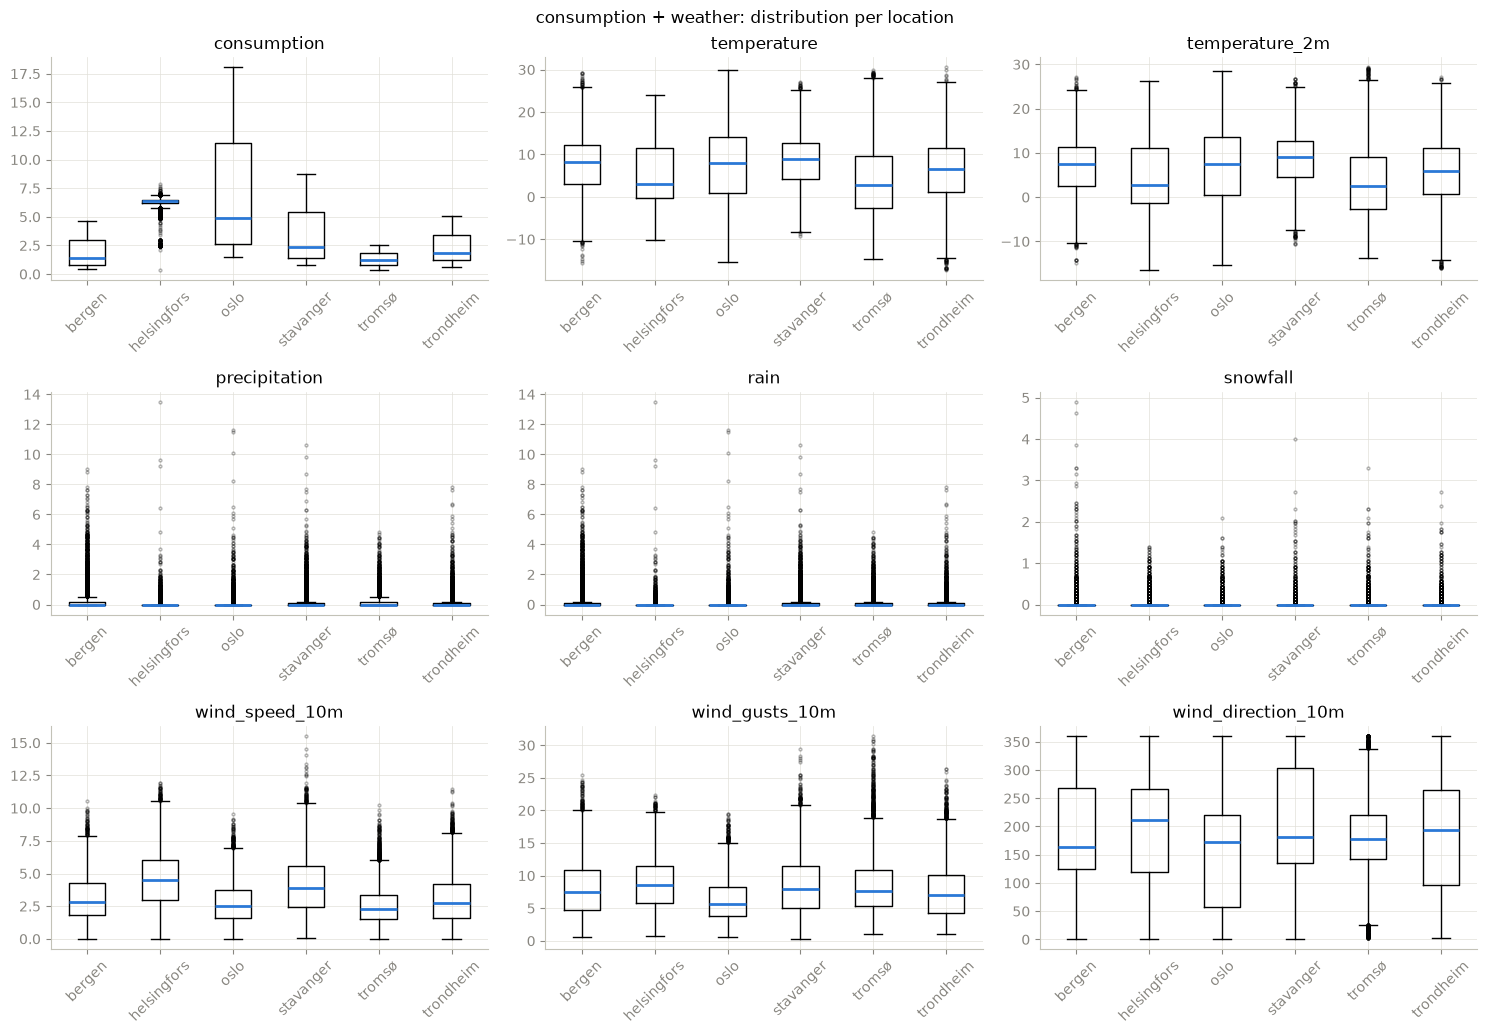

In [9]:
#distribution of values
merged_explorer = DatasetExplorer("consumption + weather", merged)
display(merged_explorer.summary())
merged_explorer.plot_distributions()

## consumption ##
* helsingfors will have very little predictive oiwer as it is a small city with little variation
* consumption+weather: all the cities follow the same pattern of consumtpion for their weather which is great. it means that helsingfors is just a small city with little consumption
* all the citites have the same type of weather, which is great

In [10]:
#Monthly means per location: seasonal level, and level shifts the temperature does not explain (portfolio changes)
monthly = merged.set_index("time").groupby("location")[["consumption", "temperature"]].resample("MS").mean()
monthly.unstack(level=0).round(2)

consumption                                      \
location                       bergen helsingfors   oslo stavanger tromsø   
time                                                                        
2022-04-01 00:00:00+00:00        0.83         NaN   2.84      1.47   1.03   
2022-05-01 00:00:00+00:00        0.76         NaN   2.39      1.25   0.94   
2022-06-01 00:00:00+00:00        0.77         NaN   2.37      1.34   0.73   
2022-07-01 00:00:00+00:00        0.82        3.52   2.32      1.31   0.64   
2022-08-01 00:00:00+00:00        0.90        5.45   2.77      1.43   0.77   
2022-09-01 00:00:00+00:00        1.00        6.17   3.50      1.65   0.95   
2022-10-01 00:00:00+00:00        1.69        6.31   6.11      2.97   1.36   
2022-11-01 00:00:00+00:00        2.33        6.35   8.84      4.30   1.75   
2022-12-01 00:00:00+00:00        3.41        6.65  13.36      6.31   2.01   
2023-01-01 00:00:00+00:00        3.40        6.46  13.11      6.14   1.94   
2023-02-01 00:00:00+00:00        3.22        6.49  12.27      5.58   1.92   
2023-03-01 00:00:00+00:00        3.16        6.35  11.70      5.49   1.96   
2023-04-01 00:00:00+00:00        2.85        6.30  10.95      5.07   1.94   

                                    temperature                               \
location                  trondheim      bergen helsingfors   oslo stavanger   
time                                                                           
2022-04-01 00:00:00+00:00      1.48        7.77         NaN   7.61      7.24   
2022-05-01 00:00:00+00:00      1.32        9.67         NaN  11.62      9.79   
2022-06-01 00:00:00+00:00      1.11       14.04         NaN  17.10     13.78   
2022-07-01 00:00:00+00:00      1.12       13.86       15.94  17.76     14.45   
2022-08-01 00:00:00+00:00      1.23       15.17       18.09  17.63     15.60   
2022-09-01 00:00:00+00:00      1.45       12.16       11.33  12.11     12.98   
2022-10-01 00:00:00+00:00      2.11        9.14        9.10   8.07     10.41   
2022-11-01 00:00:00+00:00      2.72        5.96        4.09   4.79      7.35   
2022-12-01 00:00:00+00:00      3.69       -1.03       -0.56  -4.16      0.79   
2023-01-01 00:00:00+00:00      3.67        1.56       -0.59  -1.90      2.93   
2023-02-01 00:00:00+00:00      3.63        3.64       -0.96  -0.29      4.55   
2023-03-01 00:00:00+00:00      3.63        1.19       -0.98  -1.52      2.55   
2023-04-01 00:00:00+00:00      3.51        3.72       -0.88   0.97      3.48   

                                            
location                  tromsø trondheim  
time                                        
2022-04-01 00:00:00+00:00   1.52      5.61  
2022-05-01 00:00:00+00:00   6.04      9.48  
2022-06-01 00:00:00+00:00  11.87     13.91  
2022-07-01 00:00:00+00:00  14.12     14.05  
2022-08-01 00:00:00+00:00  12.99     14.82  
2022-09-01 00:00:00+00:00   8.18     11.08  
2022-10-01 00:00:00+00:00   3.65      7.37  
2022-11-01 00:00:00+00:00  -1.55      4.07  
2022-12-01 00:00:00+00:00  -5.08     -4.43  
2023-01-01 00:00:00+00:00  -3.16     -0.30  
2023-02-01 00:00:00+00:00  -1.34      0.95  
2023-03-01 00:00:00+00:00  -5.45     -1.93  
2023-04-01 00:00:00+00:00  -1.85     -1.03

helsingfors has **nan** data as it lacks data for the first few weeks

In [11]:
#use PCA to draw clustering
#Each (location, UTC day) becomes a 24-hour profile divided by its daily mean,
#so PCA sees the shape of the day and not the size of the portfolio
hourly = consumption.assign(date=consumption["time"].dt.normalize(), hour=consumption["time"].dt.hour)
profiles = hourly.pivot_table(index=["location", "date"], columns="hour", values="consumption").dropna()  # drops partial and 0 MW days
profiles = profiles.div(profiles.mean(axis=1), axis=0)
daily_temp = hourly.groupby(["location", "date"])["temperature"].mean().loc[profiles.index]

In [12]:
pca = PCA(n_components=2)
components = pd.DataFrame(pca.fit_transform(profiles), index=profiles.index, columns=["PC1", "PC2"])
print(f"Explained variance ratio: {pca.explained_variance_ratio_.round(3)}")

Explained variance ratio: [0.485 0.306]


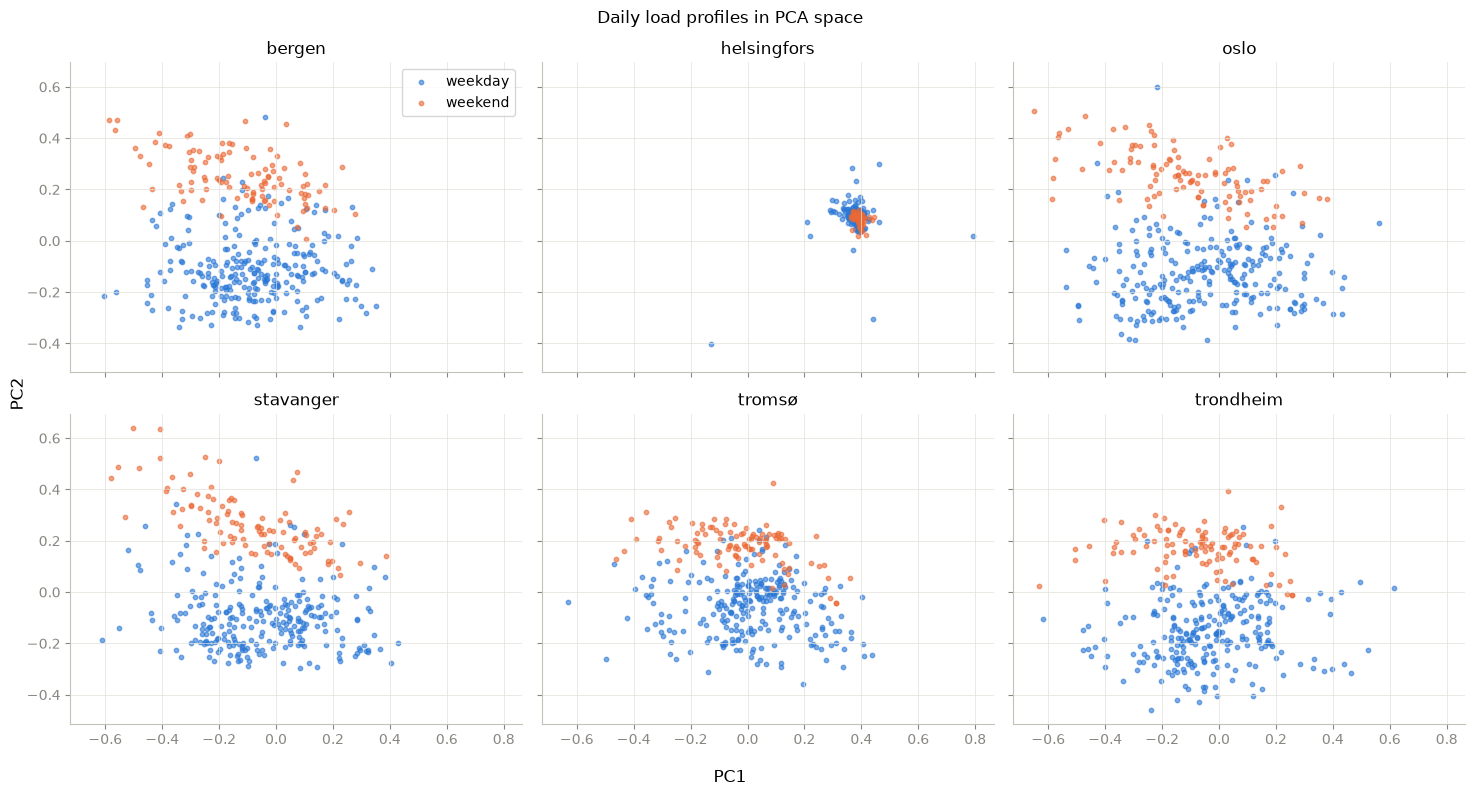

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for ax, (location, group) in zip(axes.flat, components.groupby(level="location")):
    weekend = group.index.get_level_values("date").dayofweek >= 5
    ax.scatter(group.loc[~weekend, "PC1"], group.loc[~weekend, "PC2"], s=10, alpha=0.6, color=BLUE, label="weekday")
    ax.scatter(group.loc[weekend, "PC1"], group.loc[weekend, "PC2"], s=10, alpha=0.6, color=ORANGE, label="weekend")
    ax.set_title(location)
axes[0, 0].legend()
fig.supxlabel("PC1")
fig.supylabel("PC2")
fig.suptitle("Daily load profiles in PCA space")
fig.tight_layout()
plt.show()

nice, data is clustered over weekend VS weekday

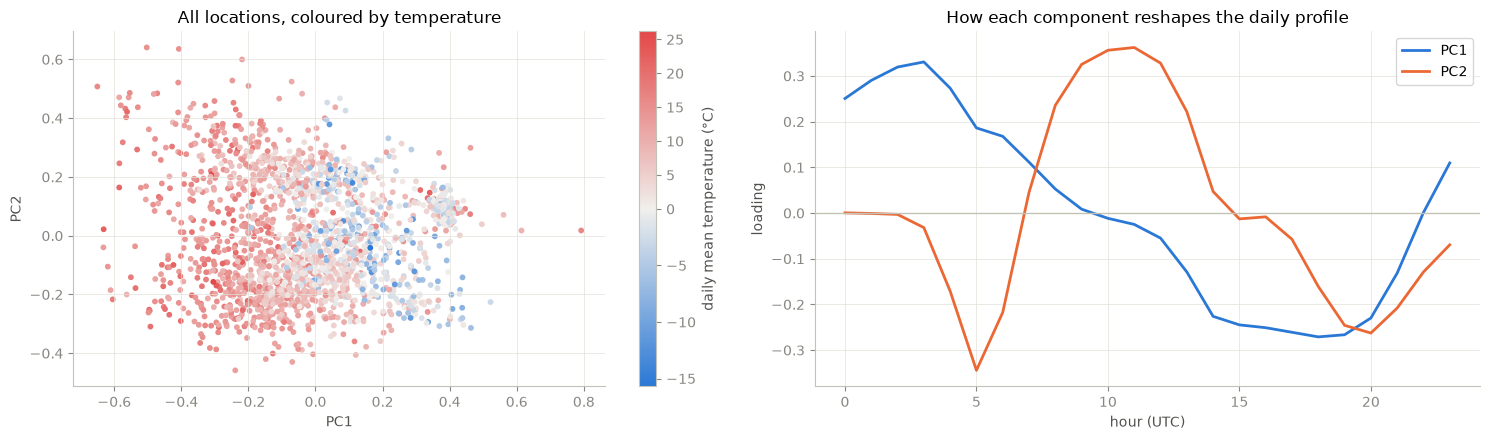

In [14]:
fig, (ax_scatter, ax_load) = plt.subplots(1, 2, figsize=(15, 4.5))
points = ax_scatter.scatter(components["PC1"], components["PC2"], c=daily_temp, cmap=DIVERGING,
                            norm=TwoSlopeNorm(vcenter=0), s=10)
fig.colorbar(points, ax=ax_scatter, label="daily mean temperature (°C)")
ax_scatter.set(title="All locations, coloured by temperature", xlabel="PC1", ylabel="PC2")

for i, color in enumerate([BLUE, ORANGE]):
    ax_load.plot(profiles.columns, pca.components_[i], color=color, linewidth=2, label=f"PC{i + 1}")
ax_load.axhline(0, color="#c3c2b7", linewidth=1)
ax_load.set(title="How each component reshapes the daily profile", xlabel="hour (UTC)", ylabel="loading")
ax_load.legend()
fig.tight_layout()
plt.show()

not sure f we need this one

In [15]:
#covairance matrix
#Standardise within each location so portfolio size does not dominate; the covariance of z-scores is the correlation.
#wind_direction_10m is left out because it is circular (359° and 1° are neighbours)
cov_cols = merged_explorer.numeric_cols.drop("wind_direction_10m")
standardised = merged.groupby("location")[cov_cols].transform(lambda s: (s - s.mean()) / s.std())
cov = standardised.cov()

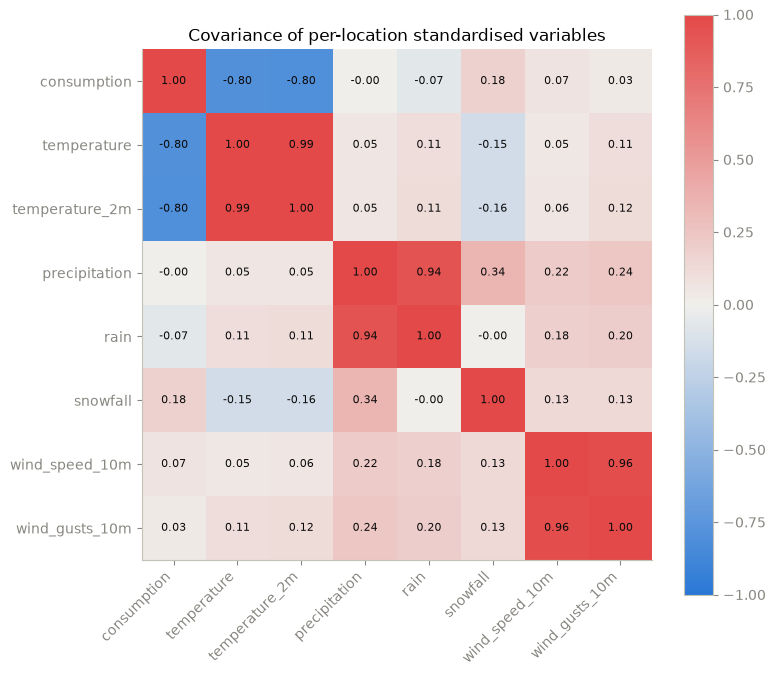

In [16]:
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cov, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(cov_cols)), cov_cols, rotation=45, ha="right")
ax.set_yticks(range(len(cov_cols)), cov_cols)
ax.grid(False)
for (i, j), value in np.ndenumerate(cov.values):
    ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8, color="#0b0b0b")
fig.colorbar(im, ax=ax)
ax.set_title("Covariance of per-location standardised variables")
fig.tight_layout()
plt.show()

In [17]:
#The link to consumption differs between locations, so show it per location as well
merged.groupby("location")[cov_cols].corr().xs("consumption", level=1).drop(columns="consumption").round(2)

,temperature,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,wind_gusts_10m
location,,,,,,,
bergen,-0.78,-0.79,0.02,-0.04,0.19,0.07,0.05
helsingfors,-0.60,-0.62,0.02,-0.04,0.12,0.11,0.06
oslo,-0.86,-0.86,-0.01,-0.07,0.20,-0.03,-0.12
stavanger,-0.78,-0.78,0.07,0.02,0.18,0.10,0.05
tromsø,-0.86,-0.86,-0.05,-0.12,0.18,0.04,0.08
trondheim,-0.84,-0.84,-0.07,-0.15,0.19,0.12,0.09


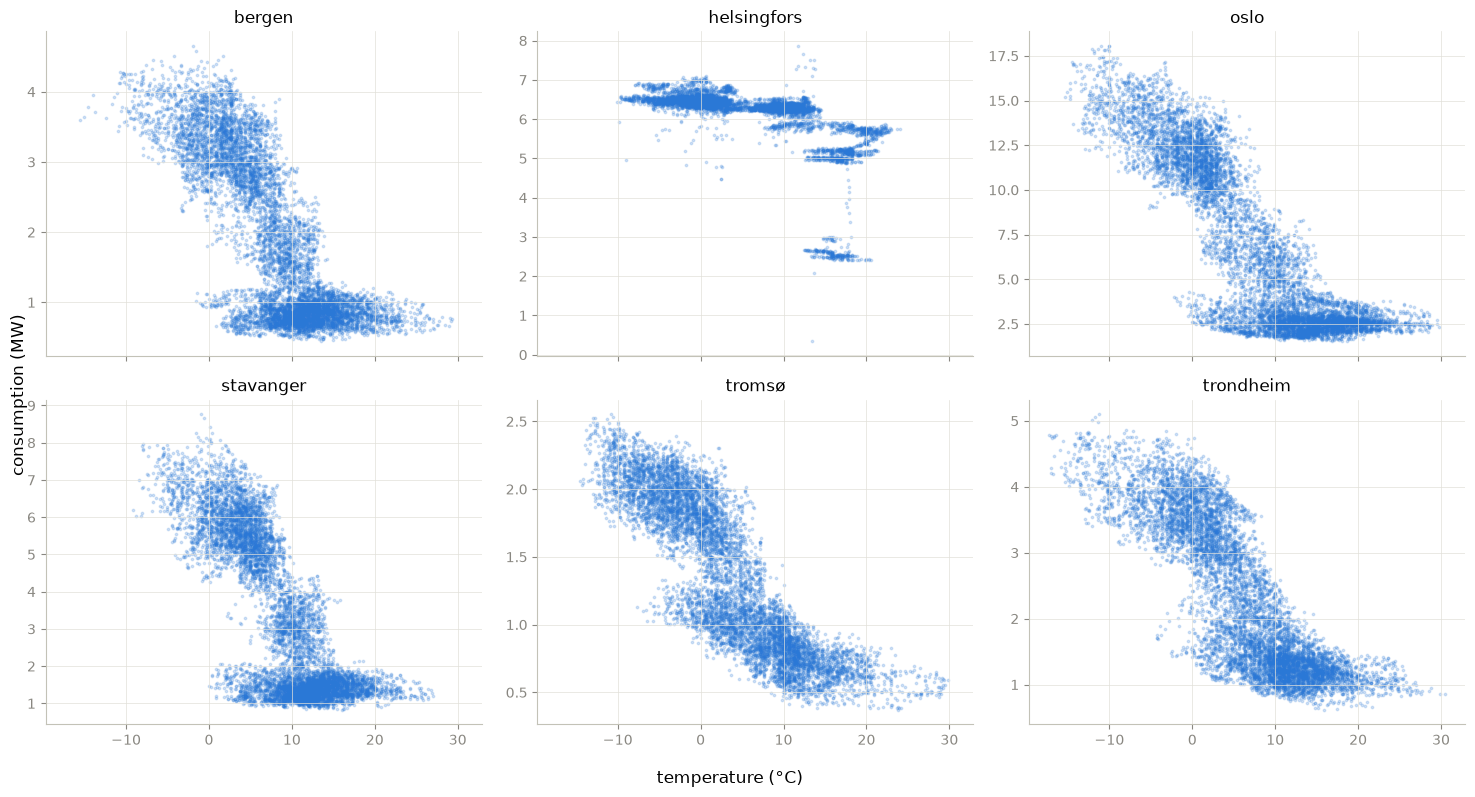

In [18]:
#Covariance only captures linear dependence; the scatter shows whether the temperature effect bends (heating threshold)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, (location, group) in zip(axes.flat, merged.groupby("location")):
    ax.scatter(group["temperature"], group["consumption"], s=3, alpha=0.2, color=BLUE)
    ax.set_title(location)
fig.supxlabel("temperature (°C)")
fig.supylabel("consumption (MW)")
fig.tight_layout()
plt.show()

## Findings
* **Missing values:** no NaNs, gaps or duplicate hours in either file. Helsingfors reports 0 MW for its first 32 hours (2022-07-14 21:00 to 2022-07-16 04:00 UTC); these are treated as missing.
* **Distributions:** the consumption level differs a lot between locations (Oslo largest, Tromsø smallest), so errors should also be compared relative to level (nMAE). Precipitation, rain and snowfall are zero most hours.
* **Level shifts:** at similar temperatures, Norwegian consumption in October 2022 is roughly 1.3 to 2 times the April 2022 level (Oslo 2.8 MW at 7.6 °C in April vs 6.1 MW at 8.1 °C in October). Helsingfors ramps up from about 2.6 to 6.3 MW during July to September 2022. This points to portfolio changes, which lagged consumption features capture but temperature alone does not.
* **PCA (clustering):** two components explain about 79 % of the variation in daily profile shape. PC2 separates weekdays from weekends in all Norwegian locations. PC1 follows temperature: cold days have a flatter profile (relatively more night consumption). Helsingfors has an almost flat profile with no weekend effect.
* **Covariance:** within a location, consumption and temperature have a correlation of about -0.80 (-0.60 in Helsingfors, -0.86 in Oslo and Tromsø). Wind and precipitation are only weakly related to consumption. The temperature effect is non-linear: almost flat above about 10 to 12 °C and steep below, which is consistent with a heating threshold.
* **Weather file:** `temperature_2m` correlates 0.99 with the delivered `temperature`. It is ERA5 reanalysis (observed weather), not a forecast, so it would not be available at 10:00 on the day before.